# Homework 4: Plotting and Examining Subsets of Data


## Problem 0: Imports and some fake data to mess with



In [25]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
t = np.linspace(0, np.pi*100, int(1e5))
N = 10 + np.sin(t)
bkgd = stats.norm.rvs(size=int(1e5))*np.sqrt(N) + N

## 1a) Make a scatter plot (not a line plot) of the first 1000 data points.

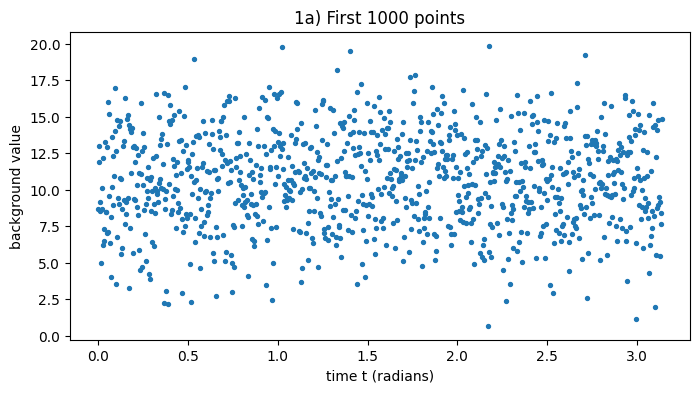

time range covered: 0.0 to 3.138482445760661  (pi = 3.142 )


In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(t[:1000], bkgd[:1000], s=8)
ax.set_xlabel("time t (radians)")
ax.set_ylabel("background value")
ax.set_title("1a) First 1000 points")
plt.show()

print("time range covered:", t[0], "to", t[999], " (pi =", round(np.pi, 3), ")")

### 1b) Generalize your code so you can make a plot of any X contiguous points (e.g. 2000 points starting at point 500), and produce an example plot of a set of data somethere in the middle of your array.
The slice is `[start : start + X]` to plot `X` contiguous points starting at index `start'.

In [27]:
def plot_window(start, X, ax=None):
    stop = start + X
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(t[start:stop], bkgd[start:stop], s=6)
    ax.set_xlabel("time t (radians)")
    ax.set_ylabel("background value")
    ax.set_title(f"{X} points starting at index {start}")
    return ax

The array has indices 0 to 99,999, so for a window somewhere in the middle would be near 50,000. For the example plot I took 2000 points starting at 50,000.

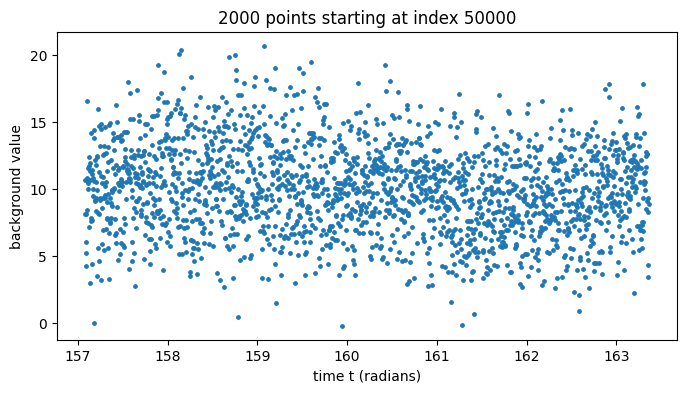

In [28]:
ax = plot_window(50000, 2000)
plt.show()

### 1c) Make a plot of the full data range, but only every 100th point.

 `bkgd[::100]`  starts at the beginning, goes at the beginning, go to the end, and takes every 100th entry: indices $0, 100, 200, \dots$.

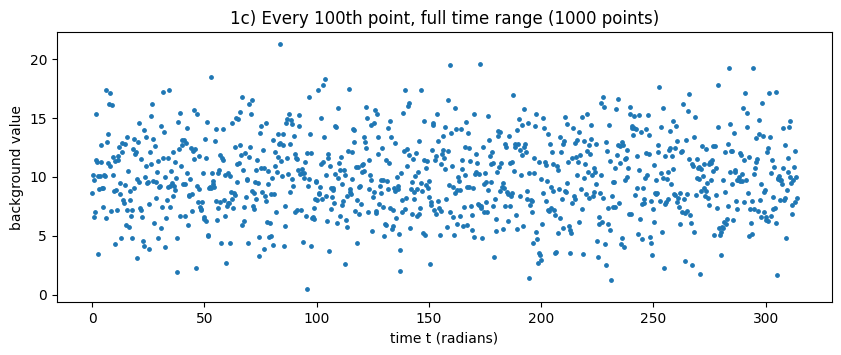

In [29]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.scatter(t[::100], bkgd[::100], s=6)
ax.set_xlabel("time t (radians)")
ax.set_ylabel("background value")
ax.set_title("1c) Every 100th point, full time range (1000 points)")
plt.show()

## Problem 2: Density

### 2a) 2D histogram

 `plt.hist2d(x, y, bins=(nx, ny))`
 cuts the $x$ range (time) into `nx` equal slices and the $y$ range (value) into `ny` equal slices. This makes a grid of `nx × ny` bins and counts how many data points $(t_i, y_i)$ fall in each rectangle.
and colors each rectangle by its count.

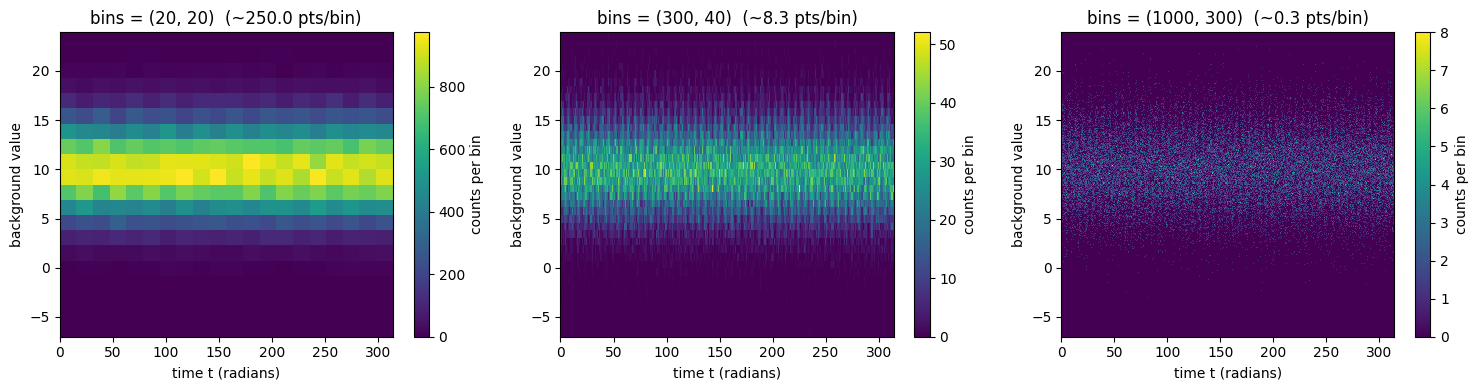

In [30]:
bin_choices = [(20, 20), (300, 40), (1000, 300)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nb_ in zip(axes, bin_choices):
    h = ax.hist2d(t, bkgd, bins=nb_, cmap="viridis")
    fig.colorbar(h[3], ax=ax, label="counts per bin")
    ax.set_title(f"bins = {nb_}  (~{1e5/(nb_[0]*nb_[1]):.1f} pts/bin)")
    ax.set_xlabel("time t (radians)")
    ax.set_ylabel("background value")
plt.tight_layout()
plt.show()


### 2b) What is being plotted?

On the horizontal axis is time $t$ in radians, split into bins and on the vertical axis is the background value $y$, split into bins. The color of each rectangle shows how many of the 100,000 data points fall inside that rectangle. Dark purple means few or none, and bright yellow means the most, which is shown on the colorbar on the right.

So a bright band means the data tends to cluster there. And the band's center is the mean at that time.

## Problem 3: Folding


### 3a) Fold at period $2\pi$


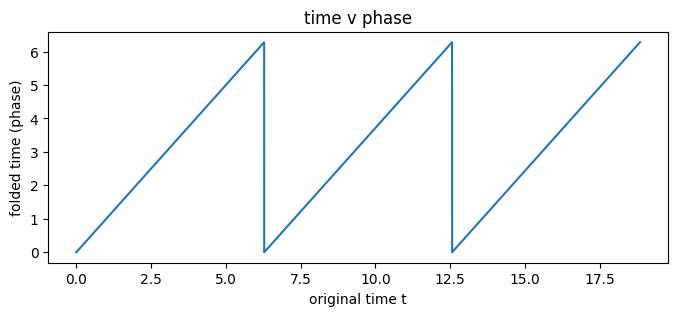

In [31]:
phase = t % (2*np.pi)       # the phase

fig, ax = plt.subplots(figsize=(8, 3))
mask = t < 6*np.pi
ax.plot(t[mask], phase[mask])
ax.set_xlabel("original time t")
ax.set_ylabel("folded time (phase)")
ax.set_title("time v phase")
plt.show()

Scatter plot of all folded data:

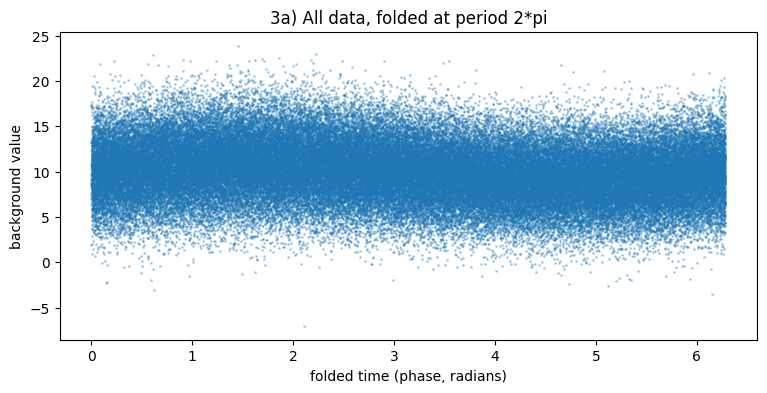

In [32]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(phase, bkgd, s=1, alpha=0.3)
ax.set_xlabel("folded time (phase, radians)")
ax.set_ylabel("background value")
ax.set_title("3a) All data, folded at period 2*pi")
plt.show()

### 3b) 2D histogram of the folded data

`phase` on the horizontal axis. I use 100 phase bins and 50 value bins (average 20 points per cell).

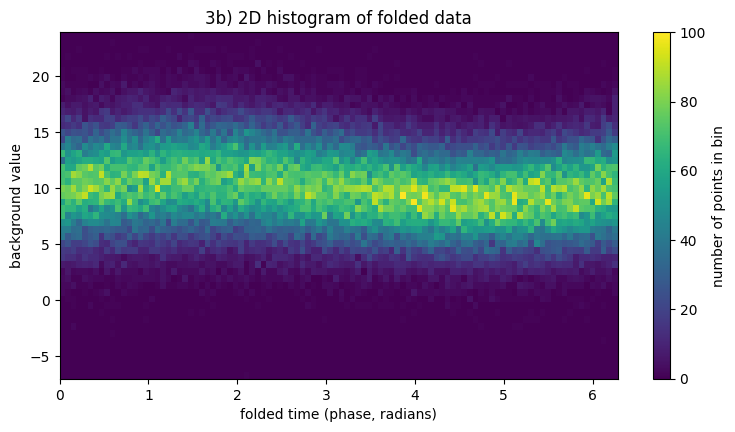

In [33]:
fig, ax = plt.subplots(figsize=(9, 4.5))
h = ax.hist2d(phase, bkgd, bins=(100, 50), cmap="viridis")
fig.colorbar(h[3], ax=ax, label="number of points in bin")
ax.set_xlabel("folded time (phase, radians)")
ax.set_ylabel("background value")
ax.set_title("3b) 2D histogram of folded data")
plt.show()